# ماتریس اغتشاش و معیارهای ارزیابی — نوت‌بوک همراه ارائهٔ دوم 🎯

**درس داده‌کاوی و یادگیری ماشین** | استاد درس: دکتر محمدرضا سلطان آقایی | ارائه‌دهنده: [نام و نام‌خانوادگی شما]

همراهِ اسلایدهای ۱۳ تا ۱۵ ارائهٔ دوم: ماتریس اغتشاش، هفت معیار طبقه‌بندی، تلهٔ Accuracy در دادهٔ نامتوازن، و ROC/MCC روی دادهٔ واقعی.

**ساختار:**
۱. مثال دیابت: از ماتریس اغتشاش تا همهٔ معیارها (دستی + sklearn)
۲. تلهٔ Accuracy در دادهٔ نامتوازن
۳. ROC و AUC روی دادهٔ واقعی سرطان پستان
۴. MCC — معیار متوازن
۵. تمرین‌های پیشنهادی
---
### 🛠 راهنمای استفاده
- **ابزار:** همهٔ کدها در **Google Colab** اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: **Shift+Enter** یا منوی Runtime ▸ Run all).
- **یادگیری پایتون، از صفر:** [W3Schools — Python Tutorial](https://www.w3schools.com/python/default.asp) — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.
- **هر سلول:** توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.


## ۱) مثال دیابت (همان اعداد اسلاید ۱۳)

غربالگری ۲۰۰ بیمار: **TP=45، FN=5، FP=10، TN=140**. اول همهٔ معیارها را **دستی** حساب می‌کنیم، بعد با sklearn چک می‌کنیم:

In [1]:
# محاسبهٔ دستی معیارها از ماتریس دیابت (TP=45, FN=5, FP=10, TN=140) — همان اسلاید ۱۱
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TP, FN, FP, TN = 45, 5, 10, 140
total = TP + FN + FP + TN

manual = {
    'Accuracy':  (TP + TN) / total,
    'Precision': TP / (TP + FP),
    'Recall (Sensitivity)': TP / (TP + FN),
    'F1': 2 * (TP/(TP+FP)) * (TP/(TP+FN)) / ((TP/(TP+FP)) + (TP/(TP+FN))),
    'Specificity': TN / (TN + FP),
    'NPV': TN / (TN + FN),
}
for k, v in manual.items():
    print(f'{k:22s} = {v:.3f}')

Accuracy               = 0.925
Precision              = 0.818
Recall (Sensitivity)   = 0.900
F1                     = 0.857
Specificity            = 0.933
NPV                    = 0.966


In [2]:
# همان مقادیر با sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, matthews_corrcoef)

y_true = np.r_[np.ones(TP+FN), np.zeros(TN+FP)]          # 50 مبتلا، 150 سالم
y_pred = np.r_[np.ones(TP), np.zeros(FN), np.ones(FP), np.zeros(TN)]

print('accuracy :', round(accuracy_score(y_true, y_pred), 3))
print('precision:', round(precision_score(y_true, y_pred), 3))
print('recall   :', round(recall_score(y_true, y_pred), 3))
print('f1       :', round(f1_score(y_true, y_pred), 3))
print('MCC      :', round(matthews_corrcoef(y_true, y_pred), 3))
print('confusion matrix (rows=actual, cols=pred):')
print(confusion_matrix(y_true, y_pred))

accuracy : 0.925
precision: 0.818
recall   : 0.9
f1       : 0.857
MCC      : 0.808
confusion matrix (rows=actual, cols=pred):
[[140  10]
 [  5  45]]


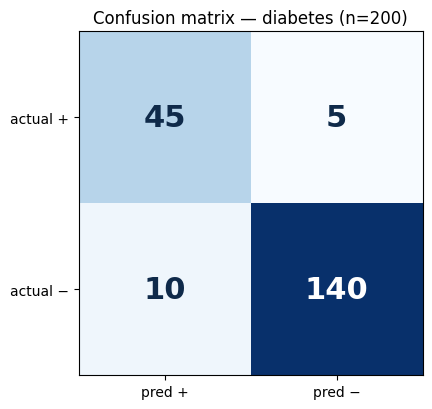

In [3]:
# رسم ماتریس اغتشاش دیابت (n=200) — خانه‌های تیره‌تر = تشخیص درست
fig, ax = plt.subplots(figsize=(5.6, 4.2))
cm = np.array([[45, 5], [10, 140]])
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]}', ha='center', va='center', fontsize=22, fontweight='bold',
                color='white' if cm[i, j] > 80 else '#0F2A4A')
ax.set_xticks([0, 1], ['pred +', 'pred −']); ax.set_yticks([0, 1], ['actual +', 'actual −'])
ax.set_title('Confusion matrix — diabetes (n=200)')
plt.tight_layout(); plt.show()

**ترادف‌ها را یادتان باشد (اسلاید ۱۴):** Sensitivity = Recall = TPR و PPV = Precision.
**کدام معیار مهم‌تر است؟** به هزینهٔ خطا بستگی دارد: اگر FN گران است (سرطان تشخیص‌داده‌نشده) → **Recall**؛ اگر FP گران است (اسپم‌شدن ایمیل مهم) → **Precision**؛ اگر هر دو مهم‌اند → **F1**.

## ۲) تلهٔ Accuracy در دادهٔ نامتوازن

۲۰۰ تراکنش که فقط **۲** تایش تقلب است. مدل تنبل که «همیشه سالم» جواب می‌دهد چه امتیازی می‌گیرد؟

In [4]:
# تلهٔ Accuracy: مدلی که همه را «سالم» اعلام می‌کند — دقت ۹۹٪ اما Recall صفر!
y_true2 = np.r_[np.zeros(198), np.ones(2)]        # 198 سالم، 2 تقلب
y_pred2 = np.zeros(200, dtype=int)                  # مدل: همه را سالم اعلام کن!

print('accuracy:', accuracy_score(y_true2, y_pred2))          # ۹۹٪ !!
print('recall  :', recall_score(y_true2, y_pred2, zero_division=0))   # صفر — هیچ تقلبی پیدا نشد
print('MCC     :', matthews_corrcoef(y_true2, y_pred2))       # صفر — مدل واقعاً هیچ اطلاعاتی ندارد

accuracy: 0.99
recall  : 0.0
MCC     : 0.0


**دقت ۹۹٪ و مدل کاملاً بی‌فایده!** در دادهٔ نامتوازن هرگز تنها به Accuracy تکیه نکنید.

## ۳) ROC و AUC روی دادهٔ واقعی سرطان پستان

دادهٔ تشخیصی سرطان پستان sklearn (۵۶۹ نمونه، ۳۰ ویژگی). رگرسیون لجستیک آموزش می‌بینیم و **منحنی ROC** را رسم می‌کنیم: TPR در برابر FPR وقتی آستانهٔ تصمیم را جابه‌جا می‌کنیم.

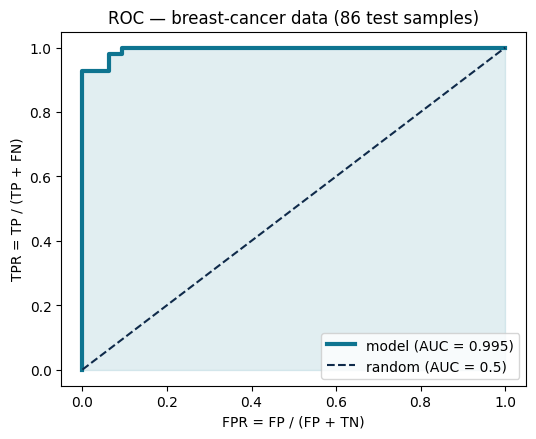

AUC: 0.9948


In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

bc = load_breast_cancer()
Xtr, Xte, ytr, yte = train_test_split(bc.data, bc.target, test_size=.15,
                                      random_state=42, stratify=bc.target)
# (یادآوری ارائهٔ اول: برای مدل‌های فاصله‌محور مثل SVM نرمال‌سازی حیاتی است؛
#  رگرسیون لجستیک با max_iter بالا این‌جا بدون آن هم همگرا می‌شود)
lr = LogisticRegression(max_iter=5000, random_state=42).fit(Xtr, ytr)
proba = lr.predict_proba(Xte)[:, 1]

fpr, tpr, _ = roc_curve(yte, proba)
plt.figure(figsize=(6, 4.6))
plt.plot(fpr, tpr, lw=3, color='#0E7490', label=f'model (AUC = {roc_auc_score(yte, proba):.3f})')
plt.plot([0, 1], [0, 1], '--', color='#0F2A4A', label='random (AUC = 0.5)')
plt.fill_between(fpr, tpr, alpha=.12, color='#0E7490')
plt.xlabel('FPR = FP / (FP + TN)'); plt.ylabel('TPR = TP / (TP + FN)')
plt.title('ROC — breast-cancer data (86 test samples)')
plt.legend(loc='lower right'); plt.show()

print('AUC:', round(roc_auc_score(yte, proba), 4))

**تفسیر AUC:** احتمال اینکه مدل به یک نمونهٔ مثبت، امتیاز بالاتر از یک نمونهٔ منفی بدهد. ۰.۵ = حدس تصادفی، ۱ = کامل. مزیت ROC/AUC: **مستقل از آستانه** — کل طیف تصمیم‌گیری را یک‌جا می‌سنجد.

## ۴) MCC — ضریب همبستگی متیوز

$$MCC = \frac{TP\times TN - FP\times FN}{\sqrt{(TP+FP)(TP+FN)(TN+FN)(TN+FP)}}$$

هر چهار خانهٔ ماتریس را با هم می‌سنجد؛ بازهٔ [−۱, +۱] و حتی در دادهٔ نامتوازن قابل‌اعتماد:

In [6]:
def mcc_manual(tp, fn, fp, tn):
    num = tp*tn - fp*fn
    den = np.sqrt((tp+fp)*(tp+fn)*(tn+fn)*(tn+fp))
    return 0.0 if den == 0 else num/den   # قرارداد sklearn: صورت و مخرج صفر -> 0

print('مثال دیابت :', round(mcc_manual(45, 5, 10, 140), 3))
print('مدل تنبل   :', round(mcc_manual(0, 2, 0, 198), 3))
print('مدل کامل   :', round(mcc_manual(2, 0, 0, 198), 3))

# روی دادهٔ سرطان پستان
pred = (proba >= .5).astype(int)
print('سرطان پستان (sklearn):', round(matthews_corrcoef(yte, pred), 4))

مثال دیابت : 0.808
مدل تنبل   : 0.0
مدل کامل   : 1.0
سرطان پستان (sklearn): 0.9252


## ۵) جمع‌بندی و تمرین‌ها ✅

- ماتریس اغتشاش نقطهٔ شروع همهٔ ارزیابی‌هاست؛ برای مسئلهٔ n-کلاسه، n×n می‌شود.
- هفت معیار + سه پرسش: کدام خطا گران‌تر است؟ داده متوازن است؟ آستانهٔ تصمیم مهم است؟
- در دادهٔ نامتوازن: **Accuracy فریب می‌دهد** — Recall/Precision/F1/MCC/AUC را ببینید.

**تمرین‌ها:**
1. آستانهٔ `proba >= .5` را به ۰.۱ و ۰.۹ تغییر دهید — دقت و Recall هر کدام چه می‌شوند؟ منحنی مقایسه (Precision-Recall curve) را با `precision_recall_curve` رسم کنید.
2. مثال دیابت را به `TP=40, FN=10` تغییر دهید: کدام معیارها بیشترین سقوط را دارند؟
3. (یادآوری ارائهٔ اول) همان ارزیابی را برای درخت تصمیم و KNN روی همین دادهٔ سرطان پستان تکرار کنید و AUC هر سه مدل را مقایسه کنید.
4. (چالشی) تابعی بنویسید که ماتریس اغتشاش را بگیرد و جدول کامل همهٔ معیارها را برگرداند.